# Danh mục theo xu hướng khung ngày (time-series momentum), 47 coin perp

Notebook dùng `daily_trend.py` cùng thư mục, dữ liệu `reference/data_5m/`. Sửa **ô Cấu hình** rồi **Run All**.

**Luật:**
- Mỗi coin: tín hiệu = trung bình dấu của lợi nhuận `LOOKBACKS` ngày, nằm trong khoảng −1…1.
- Tỷ trọng `w = tín hiệu × ASSET_VOL / biến động / N`, tổng `|w|` tối đa `GROSS_CAP`.
- Danh sách coin: top `TOP_N` theo khối lượng 30 ngày, tính lại đầu mỗi tháng.
- Đổi vị thế mỗi thứ Hai (hoặc hằng ngày), khớp lệnh lúc 01:00 UTC sau giá đóng cửa ngày.
- Phí `COST` mỗi chiều; funding theo dữ liệu thực tế.

Bản mặc định là thiết kế đã chốt trước khi chạy (INSIGHTS §9k). Mỗi lần đổi cấu hình rồi xem kết quả là **thêm một lần thử** trên cùng dữ liệu, nên kết quả đẹp từ việc thử nhiều lần không còn là bằng chứng ngoài mẫu.

In [1]:
# CẤU HÌNH — sửa ô này trước khi chạy
LOOKBACKS = (20, 60, 120)      # số ngày nhìn lại cho dấu lợi nhuận
TOP_N = 30                     # số coin trong danh sách mỗi tháng
MIN_DAYS = 150                 # số ngày lịch sử tối thiểu
VOL_HALFLIFE = 30              # half-life (ngày) của biến động EWMA
ASSET_VOL = 0.40               # mục tiêu biến động năm cho mỗi coin (trước khi chia N)
GROSS_CAP = 2.0                # trần tổng |tỷ trọng|
REBALANCE = "weekly"           # "weekly" (thứ Hai) hoặc "daily"
COST = 0.0006                  # phí + trượt giá mỗi chiều
FUNDING = True                 # tính funding thực tế
SIDES = "both"                 # "both", "long", "short"
RANDOM_RUNS = 200              # số lần mô phỏng dấu ngẫu nhiên (0 = bỏ qua)

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / "daily_trend.py").is_file():
        sys.path.insert(0, str(parent)); break
    if (parent / "reference" / "portfolio_trend" / "daily_trend.py").is_file():
        sys.path.insert(0, str(parent / "reference" / "portfolio_trend")); break
import daily_trend as dt

cfg = dt.Config(lookbacks=tuple(LOOKBACKS), top_n=TOP_N, min_days=MIN_DAYS, vol_halflife=VOL_HALFLIFE,
                asset_vol=ASSET_VOL, gross_cap=GROSS_CAP, rebalance=REBALANCE, cost=COST, funding=FUNDING,
                sides=SIDES)
panel = dt.load_panel()
print("Bảng ngày:", panel.close.shape, panel.close.index[0].date(), "->", panel.close.index[-1].date())

Bảng ngày: (2118, 47) 2021-01-01 -> 2026-10-19


In [3]:
frame, weights, sim = dt.run(panel, cfg)
market, _, _ = dt.run(panel, dt.replace(cfg, sides="both"),
                      signal=pd.DataFrame(1.0, index=panel.close.index, columns=panel.close.columns))
market = market["return"]
btc = panel.fill["btcusdt"].pct_change().loc[frame.index[0]:]
table = pd.DataFrame({"chiến thuật": dt.metrics(frame["return"], market),
                      "long tất cả coin (theo biến động)": dt.metrics(market, market),
                      "mua-giữ BTC": dt.metrics(btc, market)}).T
display(table.round(3))
display(dt.by_year(frame).round(3))

,sharpe,sortino,cagr_at_20vol,max_dd_at_20vol,raw_ann_return,raw_ann_vol,calmar_at_20vol,alpha_ann,alpha_t_nw,beta,beta_t_nw,corr_market
chiến thuật,-0.118,-0.153,-0.043,-0.380,-0.023,0.193,-0.112,-0.014,-0.176,-0.139,-2.567000e+00,-0.231
long tất cả coin (theo biến động),0.201,0.282,0.020,-0.331,0.064,0.320,0.062,0.000,1.519,1.000,1.504697e+16,1.000
mua-giữ BTC,0.536,0.767,0.091,-0.394,0.281,0.524,0.231,0.197,1.500,1.308,2.540300e+01,0.798


,days,return,sharpe,gross_pnl,long_pnl,short_pnl,funding_pnl,cost,avg_net_exposure,avg_gross_exposure,turnover_per_year
2021,214,-0.009,-0.083,0.005,0.056,-0.051,-0.009,-0.002,0.029,0.175,3.355
2022,365,0.069,0.418,0.104,-0.121,0.225,-0.010,-0.005,-0.189,0.264,8.873
2023,365,-0.003,0.075,0.034,0.203,-0.169,-0.013,-0.007,-0.028,0.385,11.667
2024,366,-0.047,-0.116,0.008,0.196,-0.188,-0.026,-0.006,0.041,0.336,10.515
2025,365,-0.076,-0.369,-0.054,-0.067,0.013,-0.005,-0.005,-0.071,0.311,8.640
2026,292,-0.139,-0.738,-0.122,-0.009,-0.113,-0.002,-0.006,-0.183,0.423,10.384


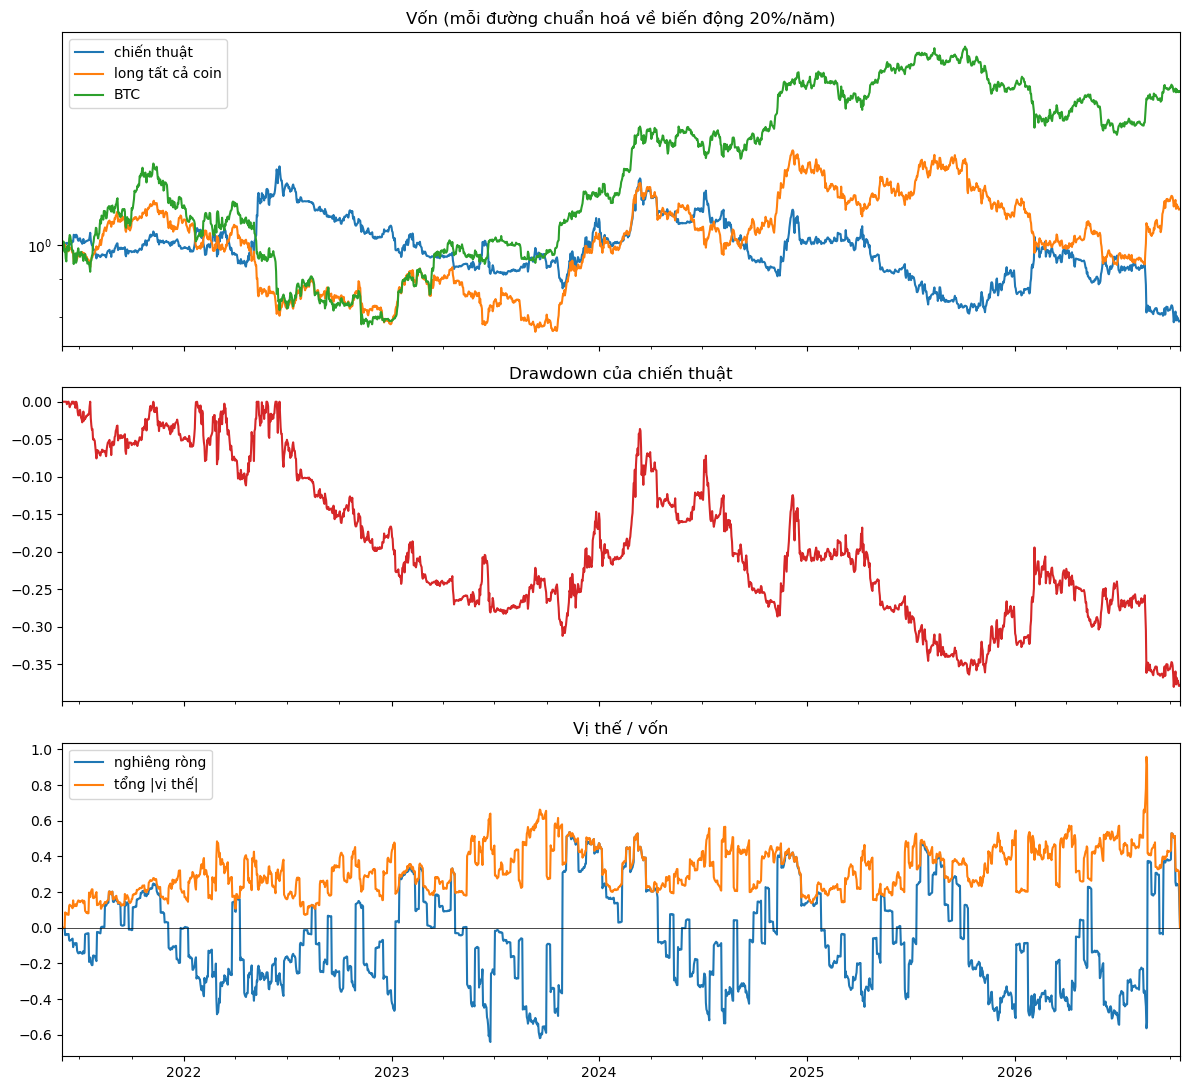

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
scale = lambda r: r * (0.20 / (r.std() * np.sqrt(365)))
for name, r in {"chiến thuật": frame["return"], "long tất cả coin": market.loc[frame.index[0]:],
                "BTC": btc}.items():
    (1 + scale(r.fillna(0))).cumprod().plot(ax=axes[0], label=name)
axes[0].set_yscale("log"); axes[0].set_title("Vốn (mỗi đường chuẩn hoá về biến động 20%/năm)"); axes[0].legend()
equity = (1 + scale(frame["return"])).cumprod()
(equity / equity.cummax() - 1).plot(ax=axes[1], color="tab:red"); axes[1].set_title("Drawdown của chiến thuật")
frame["net_exposure"].plot(ax=axes[2], label="nghiêng ròng"); frame["gross_exposure"].plot(ax=axes[2], label="tổng |vị thế|")
axes[2].axhline(0, color="k", lw=0.5); axes[2].set_title("Vị thế / vốn"); axes[2].legend()
plt.tight_layout(); plt.show()

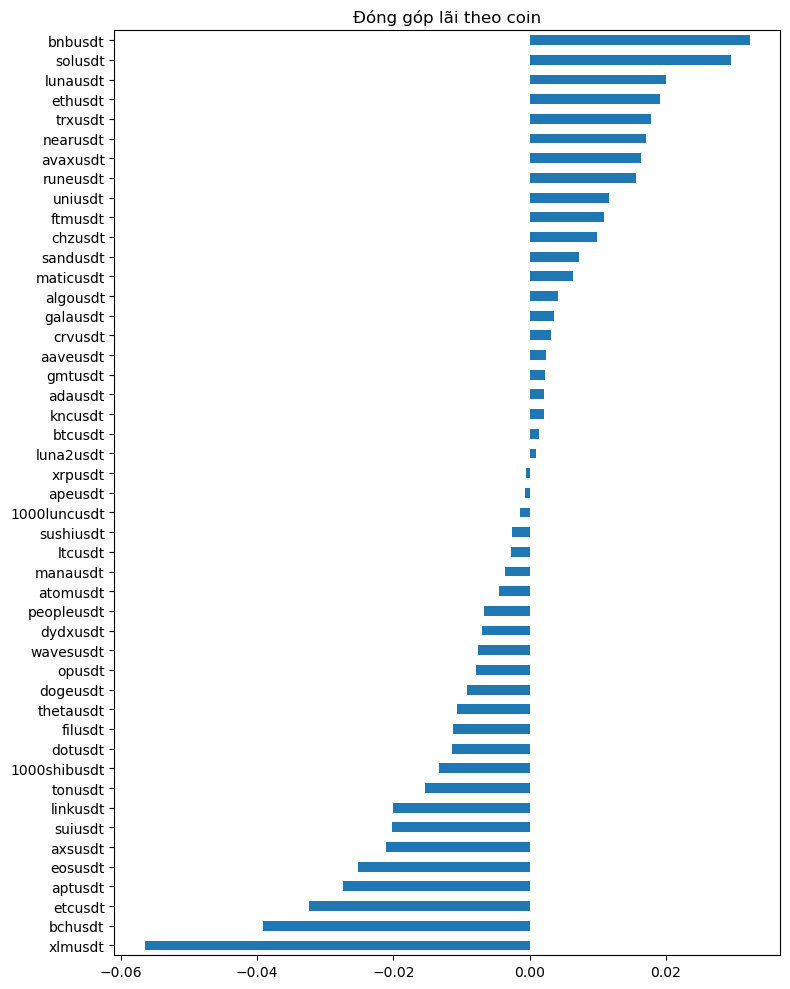

In [5]:
# Đóng góp lãi theo coin (cộng dồn lợi nhuận theo ngày, đã trừ phí và funding)
coin = pd.DataFrame(sim["coin_pnl"], index=panel.close.index, columns=panel.close.columns).loc[frame.index[0]:]
coin = coin.div(frame["equity"].shift(1).fillna(1.0), axis=0).sum().sort_values()
coin[coin != 0].plot.barh(figsize=(8, 10), title="Đóng góp lãi theo coin"); plt.tight_layout(); plt.show()

Sharpe chiến thuật -0.12; ngẫu nhiên: trung vị -0.22, phân vị 95 0.53; chiến thuật ở phân vị 62


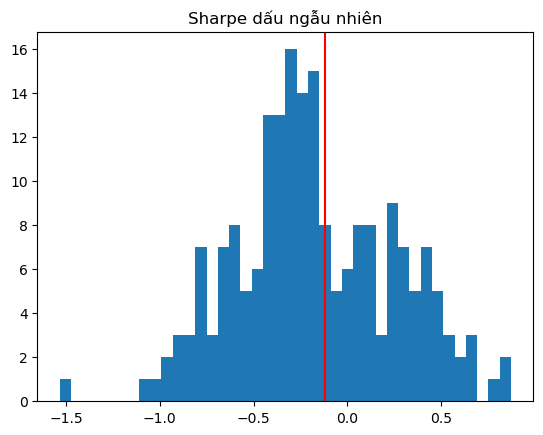

In [6]:
# Đối chứng dấu ngẫu nhiên: cùng |tỷ trọng|, dấu bốc ngẫu nhiên ở mỗi lần đổi vị thế
if RANDOM_RUNS:
    random_sharpes = dt.random_sign_benchmark(panel, weights, cfg, n=RANDOM_RUNS)
    sharpe = dt.metrics(frame["return"])["sharpe"]
    print(f"Sharpe chiến thuật {sharpe:.2f}; ngẫu nhiên: trung vị {np.median(random_sharpes):.2f}, "
          f"phân vị 95 {np.percentile(random_sharpes, 95):.2f}; chiến thuật ở phân vị {(random_sharpes < sharpe).mean()*100:.0f}")
    plt.hist(random_sharpes, bins=40); plt.axvline(sharpe, color="r"); plt.title("Sharpe dấu ngẫu nhiên"); plt.show()